# Gold and silver: explore 681 monthly observations
**January 1970–September 2026 · USD per troy ounce · Version 1.0.0**

This example uses the JSON archived at [Zenodo](https://doi.org/10.5281/zenodo.23738959), prepared by [AlyawmGold](https://alyawmgold.com/).
It runs with Python, pandas, and Matplotlib; no API calls, credentials, or network access are required.

These are nominal source-reported monthly average prices. They are not closing prices or an investment-return series.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

data_path = Path('monthly-gold-silver.json')
if not data_path.exists():
    candidates = list(Path('/kaggle/input').rglob('monthly-gold-silver.json'))
    if len(candidates) != 1:
        raise ValueError('Set data_path explicitly to the JSON from this dataset.')
    data_path = candidates[0]
metadata = json.loads(data_path.read_text(encoding='utf-8'))
prices = pd.DataFrame(metadata['data'])
fields = ['gold_average_usd_per_ounce', 'silver_average_usd_per_ounce']
expected_months = pd.period_range(metadata['from'], metadata['through'], freq='M').astype(str).tolist()
assert prices['month'].tolist() == expected_months, 'Missing, duplicate or unordered month'
assert len(prices) == metadata['recordCount']
assert prices[fields].notna().all().all()
assert (prices[fields] > 0).all().all()
assert all(float('-inf') < value < float('inf') for value in prices[fields].to_numpy().flat)
prices['month'] = pd.to_datetime(prices['month'], format='%Y-%m')
prices = prices.set_index('month')
print(f"{len(prices)} months | {metadata['from']} to {metadata['through']} | {metadata['currency']}/troy ounce")
print('Coverage, uniqueness, ordering and positive finite prices: PASS')
display(pd.concat([prices.head(3), prices.tail(3)]))


681 months | 1970-01 to 2026-09 | USD/troy ounce
Coverage, uniqueness, ordering and positive finite prices: PASS


,gold_average_usd_per_ounce,silver_average_usd_per_ounce
month,,
1970-01-01,35.193184,1.857077
1970-02-01,35.188946,1.893435
1970-03-01,35.297272,1.881808
2026-07-01,4077.902614,58.950626
2026-08-01,4394.648857,65.043235
2026-09-01,4337.398955,64.944650


## Price history
Separate vertical scales keep the two price levels readable. Both panels share the same dates and units.


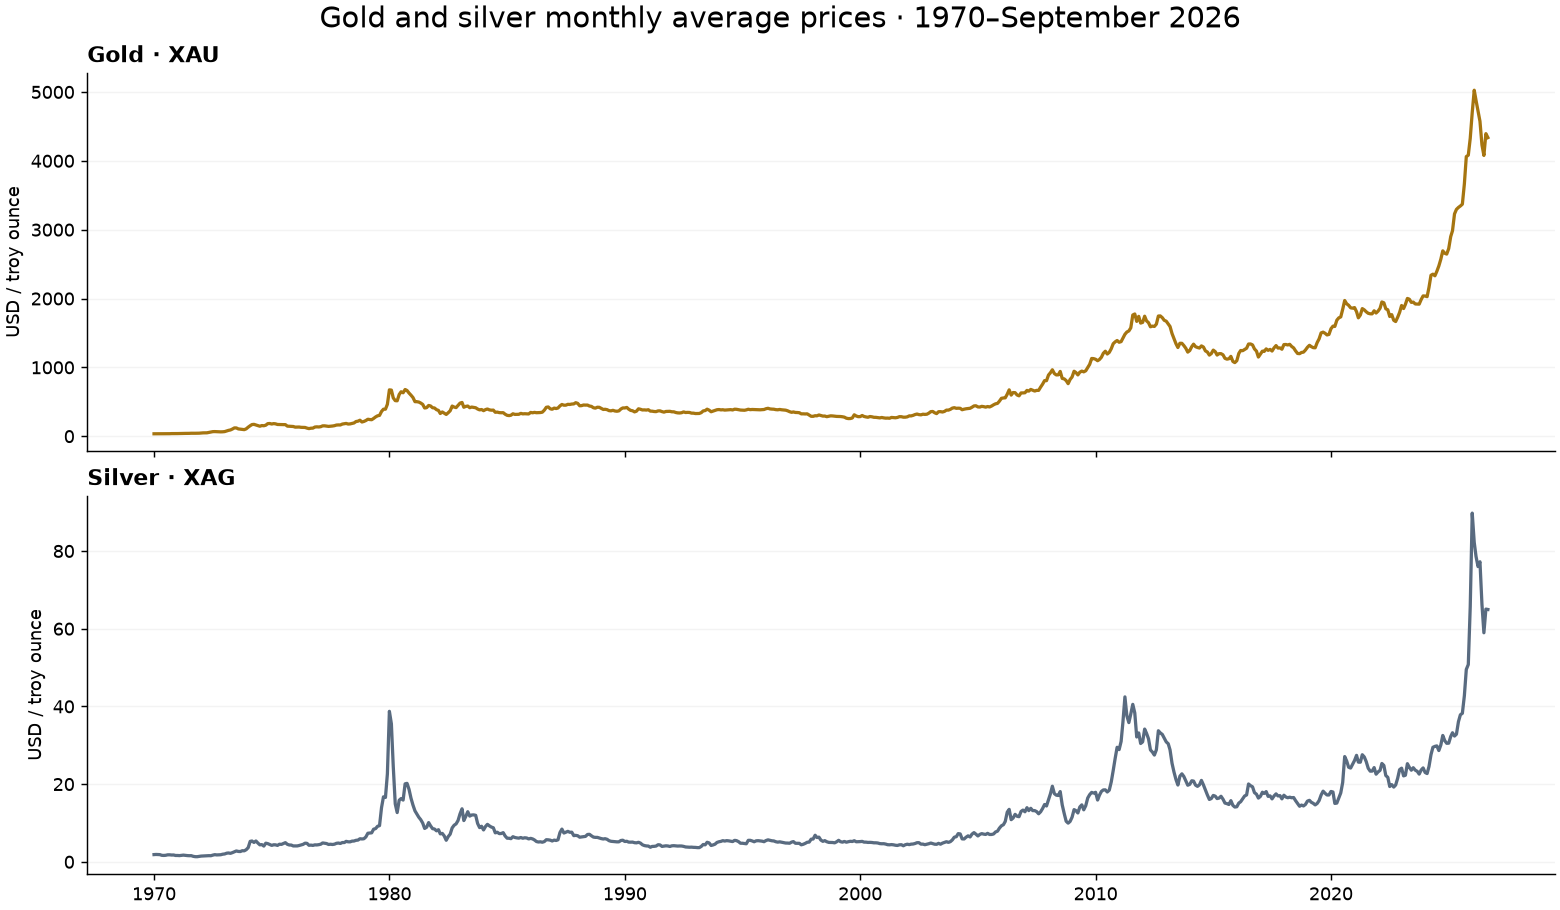

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans', 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titleweight':'bold'})
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, field, label, color in zip(axes, fields, ['Gold · XAU', 'Silver · XAG'], ['#a67510', '#596b80']):
    ax.plot(prices.index, prices[field], color=color, linewidth=1.8)
    ax.set_title(label, loc='left')
    ax.set_ylabel('USD / troy ounce')
    ax.grid(axis='y', alpha=.15)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(10))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Gold and silver monthly average prices · 1970–September 2026', fontsize=16)
plt.show()


## Ratio of monthly averages
This divides the gold monthly average by the silver monthly average. It is **not** the average of daily gold/silver ratios.


First month: 18.95; last month: 66.79


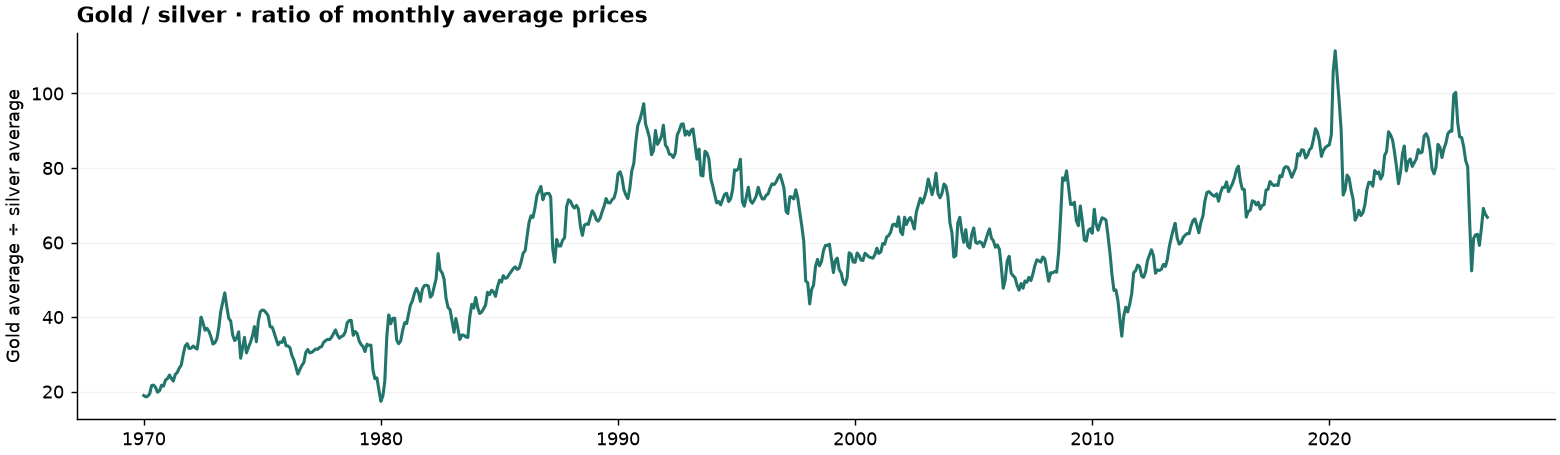

In [3]:
ratio = prices[fields[0]] / prices[fields[1]]
fig, ax = plt.subplots(figsize=(12, 3.5), layout='constrained')
ax.plot(prices.index, ratio, color='#22756b', linewidth=1.7)
ax.set_title('Gold / silver · ratio of monthly average prices', loc='left')
ax.set_ylabel('Gold average ÷ silver average')
ax.grid(axis='y', alpha=.15)
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.show()
print(f'First month: {ratio.iloc[0]:.2f}; last month: {ratio.iloc[-1]:.2f}')


## Changes in average prices
Percentage changes compare one monthly average with the preceding monthly average. They do not measure a buy-at-month-end/sell-at-month-end return. The first month has no preceding observation and stays missing.


In [4]:
changes = prices[fields].pct_change(fill_method=None).mul(100)
changes.columns = ['gold_average_change_pct', 'silver_average_change_pct']
assert changes.iloc[0].isna().all()
assert changes.iloc[1:].notna().all().all()
display(changes.tail(6).round(3))


,gold_average_change_pct,silver_average_change_pct
month,,
2026-04-01,-3.090,-3.311
2026-05-01,-3.220,1.634
2026-06-01,-7.527,-14.241
2026-07-01,-3.601,-10.996
2026-08-01,7.767,10.335
2026-09-01,-1.303,-0.152


## Retain these data-quality notes

The source values were reconciled with the collected exports. An independent comparison with World Bank monthly prices flagged differences over 5% in three observations. The original source values were retained; these differences are unresolved, not proven errors.

| Metal | Month |
| --- | --- |
| Gold | December 1980 |
| Gold | July 1983 |
| Silver | December 2025 |

Source methodology may vary across the historical series. No interpolation or exchange-rate conversion was applied. The current unfinished month is excluded. Forecasting exercises should use chronological splits and explicitly consider these caveats.

## Citation and license
AlyawmGold (2026), version 1.0.0, [DOI: 10.5281/zenodo.23738959](https://doi.org/10.5281/zenodo.23738959).
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), to the extent of rights held by the licensor. Retain acknowledgments of [AlyawmGold](https://alyawmgold.com/) and [Gold API](https://gold-api.com/).
